In [ ]:
import tensorflow as tf

a = tf.constant([1, 2, 3])
b = tf.constant([4, 5, 6])
print("Addition:", a + b)
print("Reshape:", tf.reshape(a, [3, 1]))
print("Zeros:", tf.zeros([2, 2]))
print("Eager:", tf.executing_eagerly())

@tf.function
def add(x, y):
    return x + y
print("Graph:", add(a, b))

Addition: tf.Tensor([5 7 9], shape=(3,), dtype=int32)
Reshape: tf.Tensor(
[[1]
 [2]
 [3]], shape=(3, 1), dtype=int32)
Zeros: tf.Tensor(
[[0. 0.]
 [0. 0.]], shape=(2, 2), dtype=float32)
Eager: True
Graph: tf.Tensor([5 7 9], shape=(3,), dtype=int32)


In [ ]:

import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, MinMaxScaler

# Load real dataset
df = sns.load_dataset("titanic")

# Inspect dataset
print(df.head())
print(df.isnull().sum())

# Drop column with many missing values
df = df.drop(columns=["deck"])

# Drop rows where embarked is missing
df = df.dropna(subset=["embarked"])

# Fill missing numerical values
imputer = SimpleImputer(strategy="median")
df[["age", "fare"]] = imputer.fit_transform(df[["age", "fare"]])

# Label Encoding (target variable)
le = LabelEncoder()
df["alive_encoded"] = le.fit_transform(df["alive"])

# One-Hot Encoding
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoded = ohe.fit_transform(df[["embarked"]])

encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(["embarked"]),
    index=df.index
)

df = pd.concat([df, encoded_df], axis=1)

# Normalize numerical columns
scaler = MinMaxScaler()
df[["age", "fare"]] = scaler.fit_transform(df[["age", "fare"]])

# Final output
print(df[["age", "fare", "alive_encoded",
          "embarked_C", "embarked_Q", "embarked_S"]].head())

print("Missing values after cleaning:")
print(df[["age", "fare", "embarked"]].isnull().sum())


   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck      

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0                  

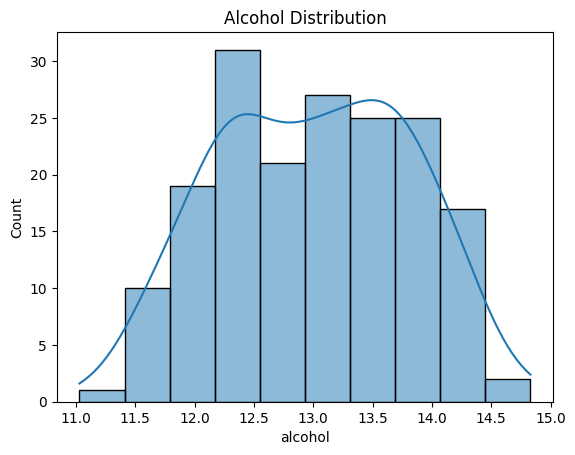

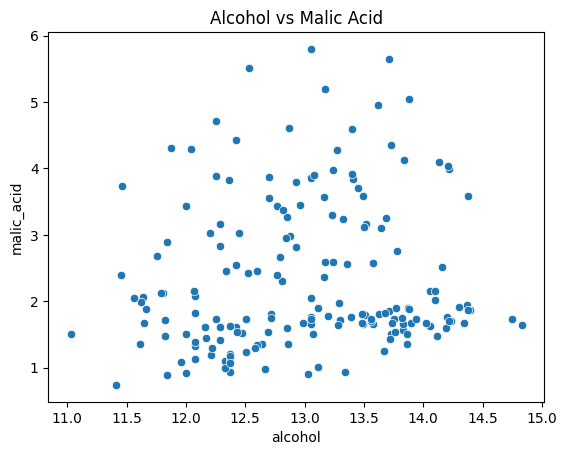

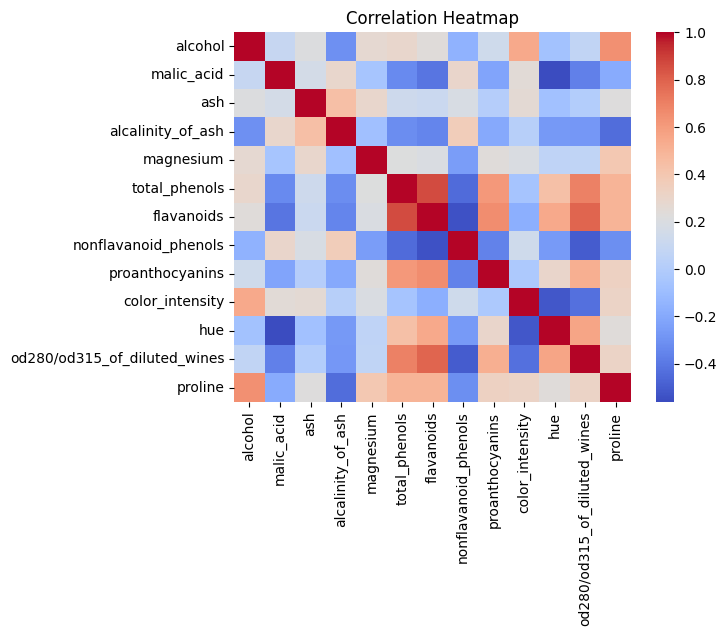

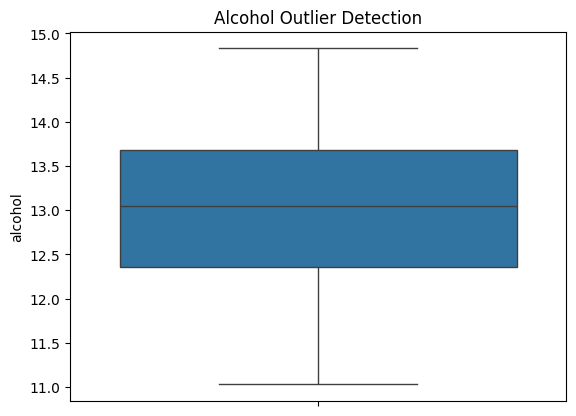

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine

# Load dataset
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)

print(df.head())

# 1. Histogram
sns.histplot(data=df, x="alcohol", bins=10, kde=True)
plt.title("Alcohol Distribution")
plt.show()

# 2. Scatter Plot
sns.scatterplot(data=df, x="alcohol", y="malic_acid")
plt.title("Alcohol vs Malic Acid")
plt.show()

# 3. Correlation Heatmap
sns.heatmap(df.corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# 4. Box Plot
sns.boxplot(data=df, y="alcohol")
plt.title("Alcohol Outlier Detection")
plt.show()


In [ ]:
!pip install gensim numpy faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 76.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 90.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [gensim]


In [ ]:

from gensim.models import Word2Vec
import gensim.downloader as api
import numpy as np
import faiss

# 1. Create text corpus
data = [
    ["dog", "cat", "animal", "pet"],
    ["dog", "puppy", "animal", "pet"],
    ["cat", "kitten", "animal", "pet"],
    ["lion", "tiger", "wild", "animal"],
    ["king", "queen", "prince", "kingdom"],
    ["man", "woman", "boy", "girl"],
    ["computer", "laptop", "technology", "programming"],
    ["python", "java", "programming", "language"],
    ["doctor", "hospital", "nurse", "patient"],
    ["teacher", "school", "student", "education"]
]

# 2. Train Word2Vec
model = Word2Vec(data, vector_size=20, min_count=1, epochs=100)

# 3. Load GloVe
glove = api.load("glove-wiki-gigaword-50")

# 4. Compare similar words
print("\nWord2Vec Results for dog:")
print(model.wv.most_similar("dog", topn=3))

print("\nGloVe Results for dog:")
print(glove.most_similar("dog", topn=3))

# 5. Create FAISS index
words = list(model.wv.index_to_key)
vectors = np.array([model.wv[w] for w in words]).astype("float32")

faiss.normalize_L2(vectors)
index = faiss.IndexFlatIP(20)
index.add(vectors)

# 6. Search similar words
query = np.array([model.wv["dog"]]).astype("float32")
faiss.normalize_L2(query)

D, I = index.search(query, 4)

print("\nFAISS Results for dog:")
print("Compared with:", [words[i] for i in I[0]])
print("Similarity scores:", D[0])



Word2Vec Results for dog:
[('technology', 0.3862510621547699), ('woman', 0.31724005937576294), ('king', 0.26331081986427307)]

GloVe Results for dog:
[('cat', 0.9218004941940308), ('dogs', 0.8513158559799194), ('horse', 0.7907583713531494)]

FAISS Results for dog:
Compared with: ['dog', 'technology', 'woman', 'king']
Similarity scores: [0.9999999  0.38625097 0.31724003 0.2633108 ]


model_index.json:   0%|          | 0.00/186 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

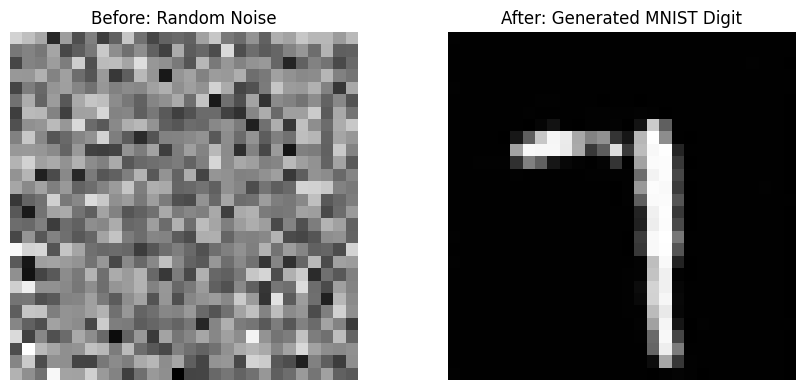

In [17]:

!pip install -q diffusers transformers accelerate torch matplotlib

import torch
import matplotlib.pyplot as plt
from diffusers import DDPMPipeline

# 1. Load pretrained MNIST DDPM
model = DDPMPipeline.from_pretrained("1aurent/ddpm-mnist")

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

# 2. Create initial random noise
seed = 42
generator = torch.Generator(device=device).manual_seed(seed)

noise = torch.randn(
    (1, model.unet.config.in_channels,
     model.unet.config.sample_size,
     model.unet.config.sample_size),
    generator=generator,
    device=device
)

# 3. Generate image from noise
generator = torch.Generator(device=device).manual_seed(seed)

result = model(
    batch_size=1,
    generator=generator,
    num_inference_steps=100
)

generated_image = result.images[0]

# 4. Display Before and After
plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(noise[0, 0].cpu().numpy(), cmap="gray")
plt.title("Before: Random Noise")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(generated_image, cmap="gray")
plt.title("After: Generated MNIST Digit")
plt.axis("off")

plt.tight_layout()
plt.show()


In [27]:

import torch
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline

# Load lightweight Stable Diffusion model
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float32,
    safety_checker=None
)

# Run on CPU
pipe = pipe.to("cpu")

# Generate image
prompt = "A cute cat sitting under a tree"

image = pipe(
    prompt,
    num_inference_steps=15,
    height=384,
    width=384
).images[0]

# Display image
plt.imshow(image)
plt.axis("off")
plt.show()

image.save("generated_cat.png")


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/15 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [6]:
!pip install -q transformers peft

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model

# 1. Load pretrained model
name = "distilbert/distilgpt2"

tokenizer = AutoTokenizer.from_pretrained(name)
model = AutoModelForCausalLM.from_pretrained(name)

tokenizer.pad_token = tokenizer.eos_token

# 2. Apply LoRA
config = LoraConfig(
    r=4,
    lora_alpha=8,
    target_modules=["c_attn"],
    fan_in_fan_out=True,
    task_type="CAUSAL_LM"
)

model = get_peft_model(model, config)
model.print_trainable_parameters()

# 3. Prepare small training data
text = "AI is transforming technology. Machine learning helps computers learn from data."

inputs = tokenizer(text, return_tensors="pt")

# 4. Fine-tune the model
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

model.train()

for i in range(5):
    optimizer.zero_grad()
    loss = model(**inputs, labels=inputs["input_ids"]).loss
    loss.backward()
    optimizer.step()
    print("Epoch:", i+1, "Loss:", round(loss.item(), 4))

print("LoRA Fine-tuning completed!")

# 5. Generate text
model.eval()

prompt = tokenizer("AI is", return_tensors="pt")

with torch.no_grad():
    output = model.generate(
        **prompt,
        max_new_tokens=30,
        pad_token_id=tokenizer.eos_token_id
    )

print(tokenizer.decode(output[0], skip_special_tokens=True))

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

trainable params: 73,728 || all params: 81,986,304 || trainable%: 0.0899


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch: 1 Loss: 4.9696
Epoch: 2 Loss: 4.7287
Epoch: 3 Loss: 4.7676
Epoch: 4 Loss: 4.5435
Epoch: 5 Loss: 4.5809
LoRA Fine-tuning completed!
AI is a new technology that allows you to create a new, unique, and unique experience.















In [26]:

!pip install -q transformers sentencepiece rouge-score

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from rouge_score import rouge_scorer

# Load pretrained model
tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")
model = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small")

# Input context
context = """
Artificial Intelligence enables machines to perform tasks
that normally require human intelligence. It is used in
healthcare, education, banking and transportation.
"""

# Function to generate text
def generate_text(prompt, max_length=50):
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True)
    outputs = model.generate(
        **inputs,
        max_new_tokens=max_length
    )
    return tokenizer.decode(outputs[0], skip_special_tokens=True)

# 1. Summarization
prompt = "Summarize this text in one sentence: " + context
summary = generate_text(prompt, 50)
print("Summary:", summary)

# 2. Question Answering
prompt = (
    "Answer using the context. Context: " + context +
    " Question: Where is AI used? Answer:"
)
answer = generate_text(prompt, 40)
print("Answer:", answer)

# 3. ROUGE Evaluation
reference = "AI is used in healthcare, education, banking and transportation."

scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"]
)

scores = scorer.score(reference, summary)

print("ROUGE Scores:", scores)


tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Summary: Artificial intelligence is a technology that can be used to perform tasks that require human intelligence.
Answer: healthcare, education, banking and transportation
ROUGE Scores: {'rouge1': Score(precision=0.125, recall=0.2222222222222222, fmeasure=0.16), 'rouge2': Score(precision=0.0, recall=0.0, fmeasure=0.0), 'rougeL': Score(precision=0.125, recall=0.2222222222222222, fmeasure=0.16)}


In [2]:
!pip install -q faiss-cpu sentence-transformers transformers sentencepiece

import faiss
from sentence_transformers import SentenceTransformer
from transformers import pipeline

# 1. Knowledge base
documents = [
    "Artificial Intelligence enables machines to perform tasks requiring human intelligence.",
    "Machine Learning is a subset of AI that learns patterns from data.",
    "Deep Learning uses neural networks with multiple layers.",
    "Natural Language Processing enables computers to understand human language.",
    "RAG combines document retrieval with language model generation."
]

# 2. Convert documents into embeddings
embedder = SentenceTransformer("all-MiniLM-L6-v2")
vectors = embedder.encode(documents).astype("float32")

# 3. Store embeddings in FAISS
index = faiss.IndexFlatL2(vectors.shape[1])
index.add(vectors)

# 4. Load pre-trained LLM using the text-generation pipeline
llm = pipeline("text-generation",
               model="gpt2",
               device=-1)

# 5. Search for relevant documents
question = "What is RAG?"
query_vector = embedder.encode([question]).astype("float32")
D, I = index.search(query_vector, k=2)

context = " ".join([documents[i] for i in I[0]])

# 6. Generate answer using retrieved context
prompt = f"Context: {context}\nQuestion: {question}\nAnswer:"

# Generate text and extract the output safely
generation = llm(prompt, max_new_tokens=60, pad_token_id=50256)[0]["generated_text"]

print("Retrieved Context:", context)
print("Question:", question)
print("Answer:", generation[len(prompt):].strip())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Retrieved Context: RAG combines document retrieval with language model generation. Machine Learning is a subset of AI that learns patterns from data.
Question: What is RAG?
Answer: RAG is a set of machine learning techniques that allow users to create simple, readable, and interactive documents.
Question: What is a document?
Answer: A document is a set of documents containing information.
Question: What is data?
Answer: Data is data stored in a database


In [3]:
!pip install -q transformers

import torch
from transformers import AutoTokenizer, AutoModel
import torch.nn.utils.prune as prune

model = AutoModel.from_pretrained("distilbert-base-uncased").eval()
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
x = tokenizer("AI is useful.", return_tensors="pt")

with torch.no_grad():
    print("Original:", model(**x).last_hidden_state.shape)

layer = model.transformer.layer[0].attention.q_lin
prune.l1_unstructured(layer, name="weight", amount=0.3)
prune.remove(layer, "weight")

with torch.no_grad():
    print("After Pruning:", model(**x).last_hidden_state.shape)

model = torch.quantization.quantize_dynamic(model, {torch.nn.Linear}, dtype=torch.qint8)

with torch.no_grad():
    print("After Quantization:", model(**x).last_hidden_state.shape)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Original: torch.Size([1, 6, 768])
After Pruning: torch.Size([1, 6, 768])


/tmp/ipykernel_29613/3327999965.py:21: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model = torch.quantization.quantize_dynamic(model, {torch.nn.Linear}, dtype=torch.qint8)
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions tha

After Quantization: torch.Size([1, 6, 768])


In [4]:
!pip install -q transformers

from transformers import pipeline

# 1. Load pre-trained model
model = pipeline("text-generation", model="distilgpt2", device=-1)

# 2. Generate text
output = model("A good leader is", max_new_tokens=30,
               do_sample=False)[0]["generated_text"]

# 3. Detect possible bias
flag_words = ["only men", "only women", "men are always", "women are always"]
flagged = any(w in output.lower() for w in flag_words)

# 4. Apply output filtering
filtered = "Output flagged due to possible bias." if flagged else output

print("Original Output:", output)
print("Bias Detected:", flagged)
print("Filtered Output:", filtered)

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Original Output: A good leader is a good leader.


























Bias Detected: False
Filtered Output: A good leader is a good leader.




























In [ ]:
from google import genai

# Gemini API key
client = genai.Client(api_key="")

# User task
task = "Create a one-day study plan for Python programming."

# Agent 1: Planner
response1 = client.models.generate_content(
    model="gemini-3.5-flash",
    contents="You are a planning agent. Create a study plan for: " + task
)

# Agent 2: Reviewer
response2 = client.models.generate_content(
    model="gemini-3.5-flash",
    contents="You are a reviewing agent. Improve this plan: " + response1.text
)

print("Agent 1:", response1.text)
print("Agent 2:", response2.text)

Agent 1: Here is a structured, intensive **1-day study plan** designed to take you from total beginner to building a working Python mini-project by the end of the day.

---

### **Overview & Goal**
* **Total Time:** ~9 Hours (including breaks)
* **Goal:** Understand basic Python syntax, core data structures, control flow, functions, and complete one hands-on project.
* **Prerequisites:** A computer, internet access, and Python 3 installed (or use an online runner like [Replit](https://replit.com/)).

---

### **Pre-Study Setup (30 Minutes Before Starting)**
1. **Environment:** Install **Python 3.x** and an IDE/editor like **VS Code** (or use Replit/Jupyter Notebook for zero setup).
2. **Setup Check:** Open your terminal/command prompt and run `python --version` (or `python3 --version`) to verify installation.

---

### **Detailed Timetable**

#### **BLOCK 1: Python Basics & Input/Output (8:30 AM – 10:30 AM)**
> **Objective:** Learn how to run code, handle data, and interact with the us